# 1 Agent를 이해하고 첫 실행 흐름 만들기

오늘은 모델의 응답이 도구 실행으로 이어지는 과정을 만듭니다. 먼저 작은 Python 코드로 책임을 나누고, 같은 흐름을 LangChain의 프롬프트·모델·도구·파서로 표현합니다. 마지막에는 CodeMate가 수정한 곱셈 Agent를 정상 입력과 실패 입력으로 검토합니다.

**사용 방법:** 위에서부터 셀을 실행합니다. 기본은 외부 API 없이 동작하는 실습입니다. `[모의]`는 고정 응답 또는 교육용 자료이며 실제 모델 품질을 뜻하지 않습니다. `RUN_LIVE=True`는 환경 파일을 확인한 뒤 실제 모델을 연결할 때만 선택합니다. 그림은 이 노트북 안에 포함되어 있습니다.

**실습 방식:** 결과를 예상하고 실행한 뒤, CodeMate에 목표·입출력·제약·검증 기준을 전달하세요. 수정 결과를 직접 확인하고 다시 지시합니다.


In [ ]:
from pathlib import Path
import sys, os
import importlib.metadata as package_version

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/courseware").is_dir()), None)
if ROOT is None:
    raise RuntimeError("프로젝트 안에서 노트북을 열어 주세요.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RUN_LIVE = False
ENABLE_LANGFUSE = False
if RUN_LIVE:
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env", override=False)
else:
    os.environ["LANGCHAIN_TRACING_V2"] = "false"
    os.environ["LANGSMITH_TRACING"] = "false"
print("실행 모드:", "실제 모델 연결" if RUN_LIVE else "모의 모델·교육용 자료")
print("Python", sys.version.split()[0])


## 1.1 Agent 사고방식과 실행 환경

**이 블록의 결과물:** 모델의 제안과 프로그램의 실행을 구별하고, 반복 흐름의 종료 조건을 설명합니다.


### 1.1.1 AI·머신러닝·LLM은 어떤 관계인가

AI는 컴퓨터가 지능적인 행동을 수행하도록 만드는 넓은 연구 분야입니다. 머신러닝은 그 안에서 **데이터를 보고 패턴을 학습하는 방법**입니다. 딥러닝은 신경망을 사용하는 머신러닝이며, LLM은 대규모 언어 자료로 학습한 모델의 한 종류입니다.

기온으로 아이스크림 판매량을 예측한다고 해 봅시다. 사람이 모든 날의 판매량을 규칙으로 적는 대신, 과거의 기온과 판매량에서 관계를 찾아 새 기온의 값을 예측합니다. 학습에서 정한 숫자와 규칙이 모델에 남고, 사용 단계에서는 새 입력을 넣습니다.

LLM은 문맥을 바탕으로 다음 토큰을 생성합니다. 토큰은 단어 전체일 수도, 단어 조각일 수도 있습니다. 그럴듯한 문장을 생성하는 능력과 **지금 필요한 사실을 확인하는 일**은 구분해서 봐야 합니다. 모델이 최신 사내 자료를 기본적으로 알고 있다고 가정하면 안 됩니다.


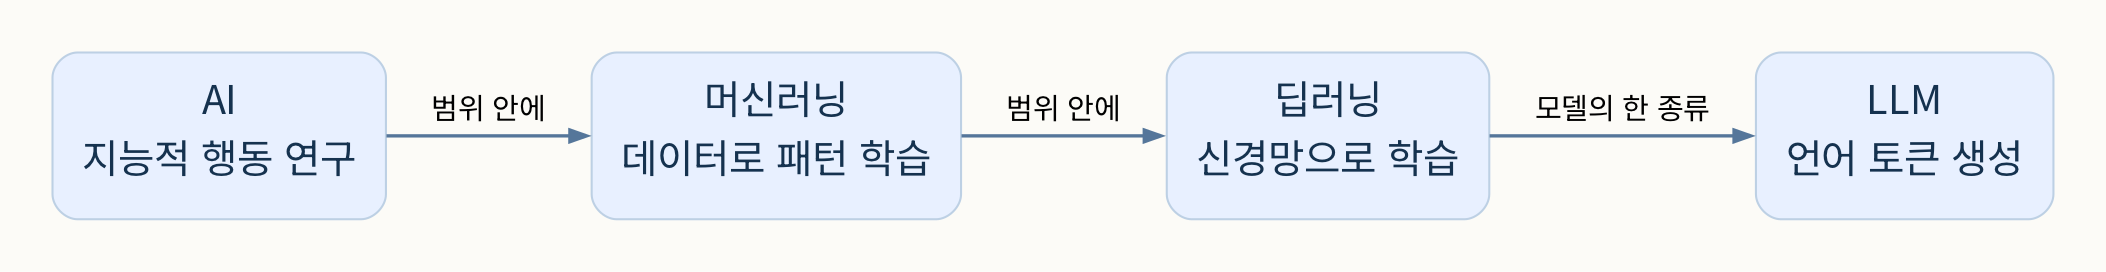

**그림 1.1.1.1 — 넓은 분야에서 언어 모델까지**

화살표는 학습 순서가 아니라 분야와 모델의 포함 관계를 나타냅니다. LLM은 모든 AI를 대표하지 않습니다.

**보면서 확인:** AI와 LLM을 같은 말로 써도 되는지 설명해 보세요.

**표현 범위:** 현대 AI의 모든 분류를 담은 도표는 아닙니다.


In [ ]:
# 이미 학습됐다고 가정한 작은 선형 모델입니다. 실제 학습 과정은 생략했습니다.
def predict_sales(temperature):
    return 12 * temperature - 100
for temperature in [20, 25, 30]:
    print(temperature, "도 → 예상 판매량", predict_sales(temperature))


**실행에서 볼 것**

25도에서 200이 나옵니다. 이는 이 식의 예측값이며 실제 판매량이 아닙니다. 100도까지 같은 식을 적용해도 현실에 맞을지 생각해 보세요.


**CodeMate와 확인하기**

> 이 코드에서 입력, 모델의 숫자, 예측값을 구분해 설명해 주세요. 학습 자료에 없던 극단적인 입력 하나를 골라 예측의 한계를 보여 주세요. 실제 판매량 데이터나 학습했다고 주장하는 코드는 추가하지 마세요.


### 1.1.2 답변에서 도구 사용으로 확장하기

날씨를 묻는 질문에 텍스트로 답하는 것과 날씨 조회 함수를 호출하는 것은 다른 동작입니다. 도구를 사용할 때 모델은 **도구 이름과 인자**를 제안합니다. 프로그램은 그 이름이 허용 목록에 있는지, 인자가 맞는지 검사한 뒤 함수를 실행합니다.

여기서 모델 출력은 실행 지시 후보입니다. 문자열을 곧바로 `eval()`로 실행하면 어떤 동작이 일어날지 통제하기 어렵습니다. 이름으로 정해진 함수를 찾고 검증된 값만 넘기는 것이 이 예제의 경계입니다.

아래 `request`는 사람이 작성한 모의 모델 출력입니다. 도구 결과도 실습용 고정값입니다. 이 단계에서는 API 호출보다 제안·검사·실행의 위치를 정확히 구분하는 데 집중합니다.


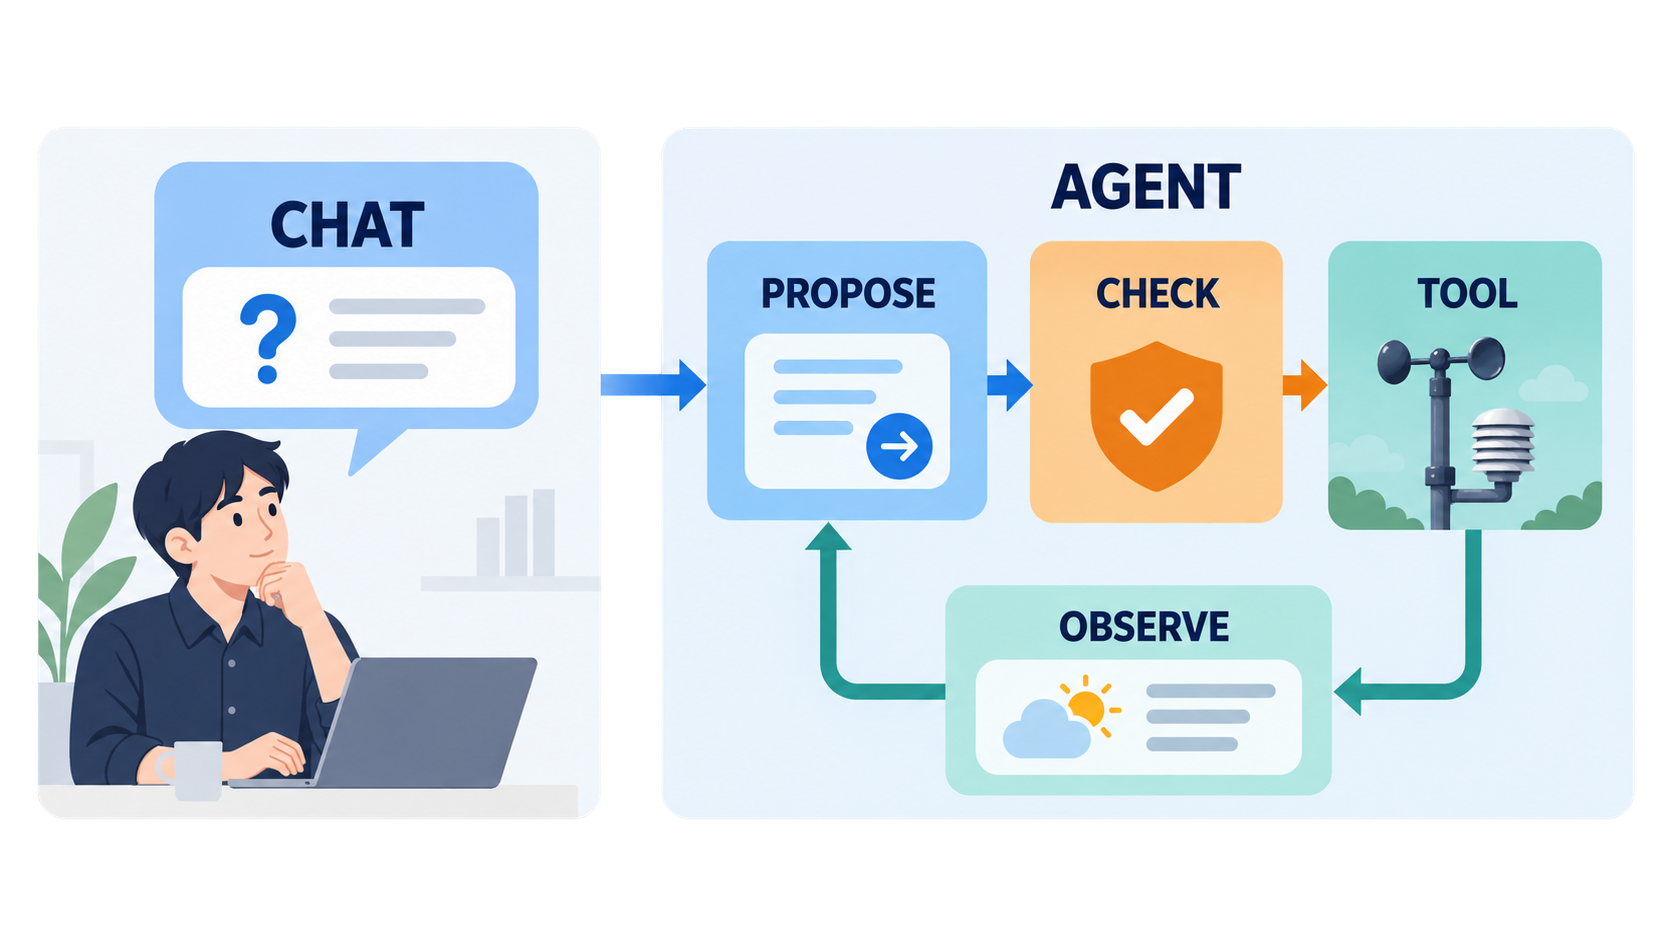

**그림 1.1.2.1 — 모델의 제안 뒤에 실행 검사가 필요합니다**

왼쪽의 대화가 오른쪽에서는 제안(PROPOSE), 검사(CHECK), 도구(TOOL), 관찰(OBSERVE)로 확장됩니다. 주황색 단계는 프로그램이 통제하는 경계입니다.

**보면서 확인:** 도구를 실행하는 주체와 도구 사용을 제안하는 주체를 구분해 보세요.

**표현 범위:** 삽화의 날씨는 예시이며 실제 관측값이 아닙니다. 모든 챗봇이 도구를 못 쓴다는 분류도 아닙니다.


In [ ]:
def get_weather(location):
    if location not in {"Dongtan", "Seoul"}:
        raise ValueError("실습에서 지원하지 않는 지역입니다.")
    return {"location": location, "weather": "흐림", "source": "모의 날씨 자료"}

def execute_request(request):
    if request.get("tool") != "get_weather":
        raise ValueError("허용하지 않은 도구입니다.")
    arguments = request.get("arguments", {})
    if set(arguments) != {"location"} or not isinstance(arguments["location"], str):
        raise ValueError("location 문자열 하나가 필요합니다.")
    return get_weather(arguments["location"])

request = {"tool": "get_weather", "arguments": {"location": "Dongtan"}}
print(execute_request(request))


**실행에서 볼 것**

출력의 source가 모의 자료임을 확인하세요. `send_email`이라는 이름은 등록된 도구가 아니므로 실행되지 않아야 합니다.


**CodeMate와 확인하기**

> execute_request에 대한 정상 사례 1개와 실패 사례 3개를 만들어 주세요. 알 수 없는 도구, 누락된 location, 숫자 location을 검사하세요. 실패 시 어떤 함수까지 실행됐는지 설명하고, eval이나 외부 API를 추가하지 마세요.


### 1.1.3 판단·실행·관찰과 종료 조건

Agent는 첫 응답으로 작업이 끝나지 않을 수 있습니다. 자료가 부족하면 검색하고, 검색 결과를 다시 입력으로 받아 다음 행동을 정합니다. 이 반복을 수업에서는 **판단 → 실행 → 관찰**로 읽습니다. 내부 사고 과정을 출력받아야 한다는 뜻은 아닙니다. 우리는 제안한 행동과 실제 실행 결과를 관찰합니다.

종료 조건에는 두 종류가 있습니다. 필요한 근거를 얻어 답변할 수 있으면 정상 완료합니다. 반복 횟수 한도에 도달하거나 허용하지 않은 도구를 요청하면 중단하고 이유를 알려야 합니다. 한도에 도달한 상태를 성공으로 표시하면 안 됩니다.

아래 코드는 관찰이 없으면 도구를 부르고, 관찰이 생기면 답하는 고정 규칙입니다. 실제 LLM의 추론 능력을 보여 주는 코드는 아니지만, 프로그램이 반복을 제어하는 위치를 드러냅니다.


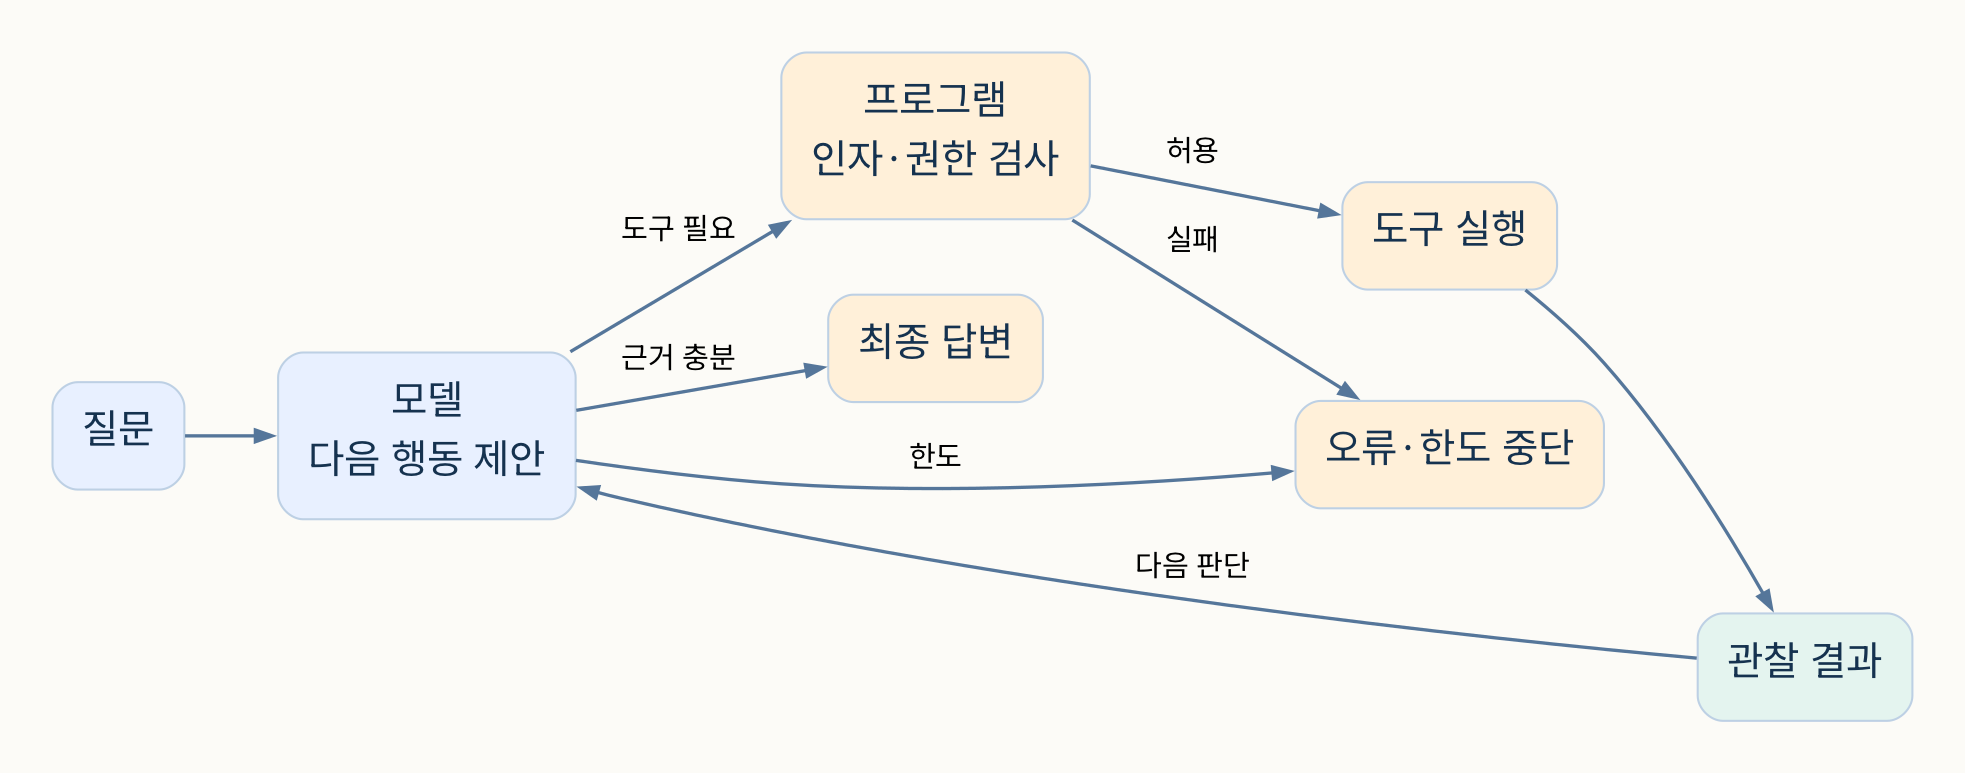

**그림 1.1.3.1 — 관찰 결과가 다음 판단의 입력으로 돌아갑니다**

도구 경로는 검사와 실행을 통과한 뒤 모델로 돌아갑니다. 답변 경로와 오류·한도 중단 경로가 따로 있습니다.

**보면서 확인:** 어느 지점에서 무한 반복을 막을 수 있는지 찾아보세요.

**표현 범위:** 재시도·다중 도구·비동기 처리는 이 기본 도식에서 생략했습니다.


In [ ]:
def run_weather_agent(location, max_steps=3):
    observation = None
    events = []
    for step in range(max_steps):
        if observation is None:
            observation = execute_request({"tool": "get_weather", "arguments": {"location": location}})
            events.append("tool")
        else:
            events.append("answer")
            return {"status": "completed", "answer": observation["weather"], "events": events}
    return {"status": "stopped", "answer": None, "events": events}
print(run_weather_agent("Dongtan"))
print(run_weather_agent("Dongtan", max_steps=1))


**실행에서 볼 것**

한도가 1이면 도구 결과는 얻었지만 답변 단계에 도달하지 못합니다. completed와 stopped의 차이를 실행 기록으로 설명해 보세요.


**CodeMate와 확인하기**

> run_weather_agent가 실패해도 status, answer, events 형식을 유지하도록 바꿔 주세요. ValueError를 기록하고 중단하되 오류를 성공 답변으로 바꾸지 마세요. 정상 완료·한도 중단·지원하지 않는 지역의 세 사례를 실행해 비교해 주세요.


### 1.1.4 VS Code·커널·환경변수 준비

프로젝트 폴더를 VS Code로 열고 Python 및 Jupyter 확장을 확인합니다. 터미널에서 `uv sync --extra notebooks`를 실행하면 잠금 파일에 맞춰 프로젝트의 `.venv`가 준비됩니다. 노트북 우측 상단에서 이 `.venv`의 Python 커널을 선택합니다. 터미널 Python과 노트북 커널이 다르면 설치한 패키지를 찾지 못할 수 있습니다.

CodeMate는 강의장에서 제공하는 사내 확장을 사용합니다. 실제 메뉴와 연결 상태는 강의장 화면에서 확인합니다. 첫 요청은 “현재 파일의 입력·출력과 실행 방법을 설명해 주세요”로 시작하고, 제안된 변경을 읽은 뒤 적용합니다.

실제 모델 연결 정보는 루트의 `.env` 또는 선택한 환경 파일에 둡니다. 사외는 `LLM_PROVIDER=openai`, `EMBED_PROVIDER=openai`, `RAG_PROVIDER=mock`, 사내는 지정된 삼성 설정을 사용합니다. 모델명은 환경변수로 선택합니다. 연결 실패를 이유로 다른 외부 서비스로 자동 전환하지 않습니다.

모의 실습은 키 없이 가능합니다. 아래 셀은 설치 여부만 확인하고 환경변수 값은 출력하지 않습니다.


In [ ]:
for package in ["langchain", "langgraph", "ipykernel", "nbformat"]:
    print(package, package_version.version(package))
print("프로젝트 확인:", (ROOT / "pyproject.toml").exists())
print("환경 파일 존재:", (ROOT / ".env").is_file())
print("실행 파일:", Path(sys.executable).name)


**실행에서 볼 것**

모든 패키지의 버전이 출력되면 커널이 필요한 패키지를 읽은 것입니다. 환경 파일이 없어도 모의 실습은 진행할 수 있습니다.


**CodeMate와 확인하기**

> 현재 노트북의 커널과 프로젝트 실행 명령을 확인해 주세요. 환경변수는 이름과 설정 여부만 확인하고 값은 출력하지 마세요. CodeMate 연결이 확인되면 1.1.3 함수가 어떤 입력을 받는지 설명하고 아직 코드는 바꾸지 마세요.


### 1.1.5 Agent의 네 가지 책임 설명하기

지금 만든 실행 흐름을 네 문장으로 설명해 봅시다. **입력을 만든다, 다음 행동을 제안한다, 허용된 도구를 실행한다, 결과와 종료를 확인한다.** 한 함수가 여러 책임을 가질 수 있지만, 실패를 찾으려면 책임을 구별할 수 있어야 합니다.

LLM을 붙인 뒤에도 이 구조는 유지됩니다. 바뀌는 것은 다음 행동을 제안하는 부분입니다. 도구의 입력 계약, 허용 목록, 실행 기록, 종료 한도는 프로그램이 맡습니다. 따라서 모델을 바꿨다고 실행 검사가 사라지지 않습니다.

다음 블록에서는 문자열 하나 대신 역할이 붙은 메시지를 모델에 전달합니다. 메시지에 어떤 맥락을 넣고 어떤 결과를 받는지 알아야 도구 사용의 앞뒤를 연결할 수 있습니다.


In [ ]:
responsibilities = {
    "입력": request,
    "실행 경계": execute_request.__name__,
    "반복 제어": run_weather_agent.__name__,
    "확인할 결과": ["status", "answer", "events"],
}
for name, value in responsibilities.items():
    print(name, "→", value)


**CodeMate와 확인하기**

짝에게 모델을 실제로 연결할 위치와 그대로 유지할 검사를 설명하세요. CodeMate에는 “내 설명에서 제안과 실행을 혼동한 부분이 있는지 코드 줄을 근거로 검토해 주세요”라고 요청하세요.


## 1.2 LLM의 입력과 API

**이 블록의 결과물:** 대화 메시지를 구성하고 단일 요청·대화 유지·스트리밍·환경별 모델 선택을 구별합니다.


### 1.2.1 학습과 생성, 다음 토큰의 의미

학습은 데이터에서 모델의 매개변수를 조정하는 과정입니다. 생성은 이미 준비된 모델에 현재 문맥을 넣어 출력을 얻는 과정입니다. 일반적인 API 대화에서 새 메시지를 보냈다고 그 내용이 곧바로 모델의 가중치에 학습되는 것은 아닙니다.

다음 토큰 예측은 후보들에 점수를 주고 한 토큰을 선택하는 과정으로 생각할 수 있습니다. 선택한 토큰을 문맥에 붙여 다음 토큰을 생성합니다. 아래의 후보와 확률은 원리를 설명하기 위해 직접 적은 숫자입니다.

Temperature와 top-p는 생성 후보 선택에 영향을 주는 설정입니다. 지원 여부와 조합은 모델마다 다르며, 낮은 값이 사실성을 보장하지 않습니다. 이 수업은 모델별 설정을 무작정 복사하지 않고 연결된 모델의 지원 범위를 확인합니다.


In [ ]:
import random
rng = random.Random(42)
candidates = ["brown", "gray", "orange"]
weights = [0.7, 0.2, 0.1]  # 설명용으로 사람이 정한 값
samples = rng.choices(candidates, weights=weights, k=12)
print("The quick", samples[0], "fox")
print({word: samples.count(word) for word in candidates})


**실행에서 볼 것**

확률이 높은 후보가 항상 선택되지는 않습니다. 이 표는 실제 모델이 반환한 토큰 확률이 아닙니다.


**CodeMate와 확인하기**

> 후보 확률과 추출 횟수를 인자로 받도록 코드를 바꿔 주세요. 확률 합이 1이 아닌 입력과 음수 확률을 거절하세요. 난수 시드를 고정했을 때와 바꿨을 때 무엇이 달라지는지 설명해 주세요.


### 1.2.2 토큰과 컨텍스트를 관리하기

컨텍스트는 현재 요청에서 모델이 참고할 입력 공간입니다. 규칙, 최근 대화, 검색 자료, 도구 설명과 도구 결과가 이 공간을 나눠 씁니다. 출력에 필요한 여유도 고려해야 합니다. 긴 문서 전체를 넣는다고 중요한 내용이 더 잘 반영되는 것은 아닙니다.

대화가 길어지면 오래된 대화를 요약하거나 필요한 근거만 검색해 넣습니다. 요약은 원문을 줄이는 대신 세부 정보를 잃을 수 있고, 검색은 필요한 자료를 놓칠 수 있습니다. 예약 상태처럼 정확히 유지할 값은 별도 구조에 두는 편이 확인하기 쉽습니다.

실제 토큰 수는 사용하는 모델의 토크나이저로 확인해야 합니다. 아래 실험은 문서 조각의 **개수 예산**을 다루며 토큰 비용을 계산하지 않습니다. 필요한 규칙과 질문을 먼저 남기고 참고 자료를 선택하는 원리를 봅니다.


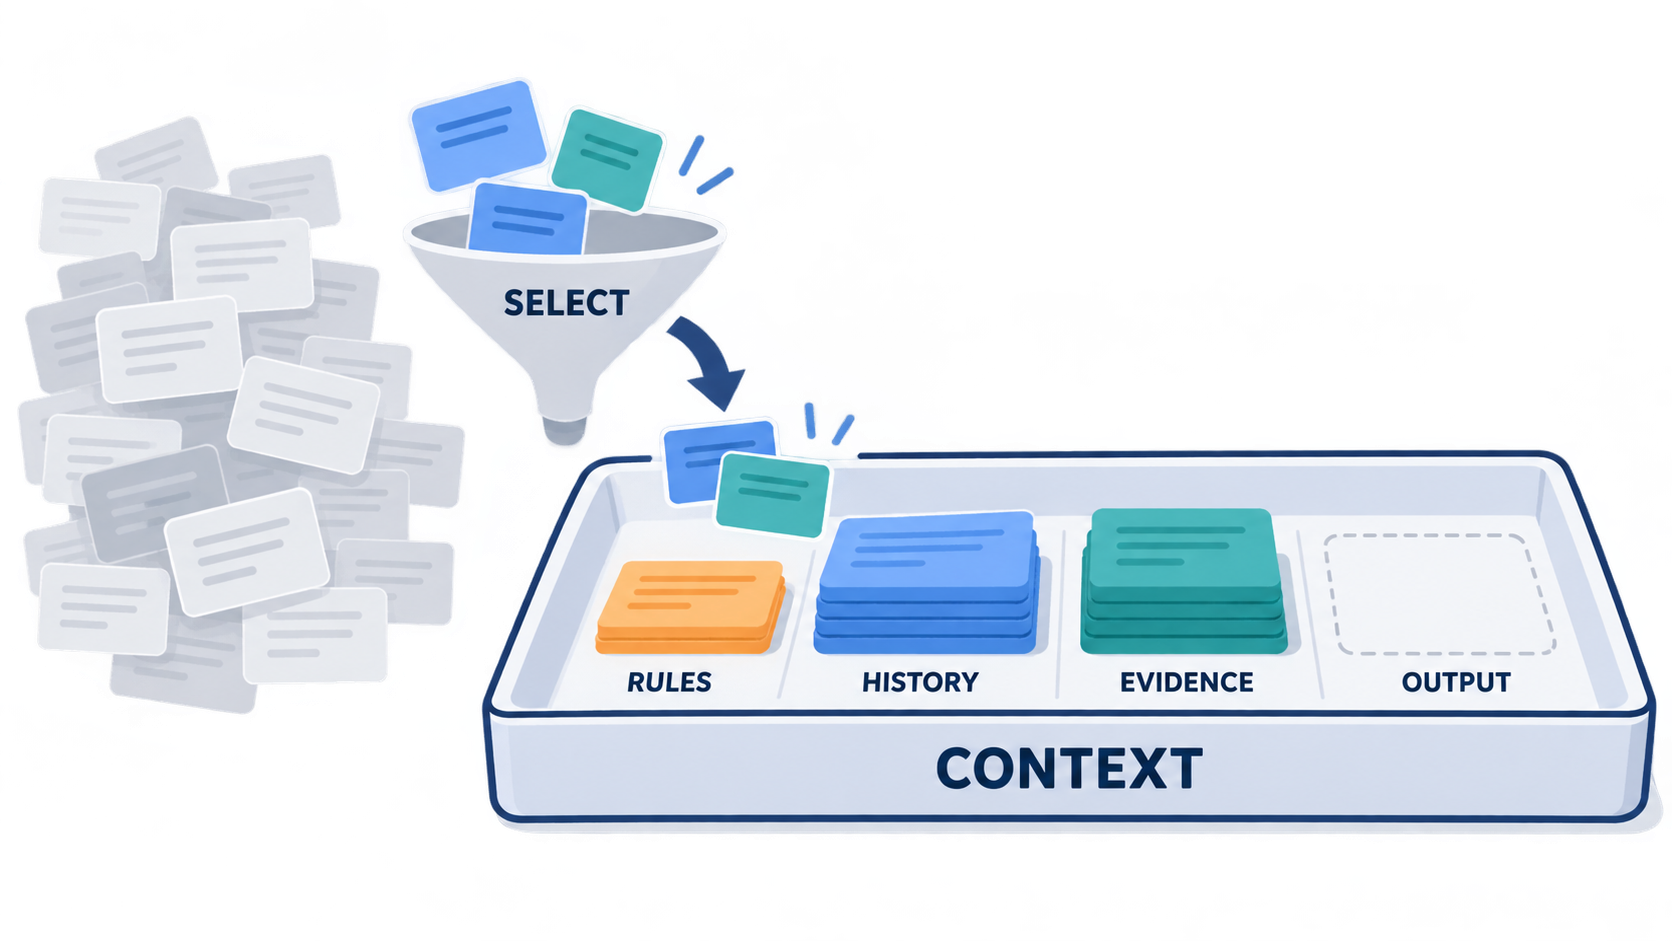

**그림 1.2.2.1 — 현재 요청에 넣을 맥락을 선택합니다**

상자는 현재 컨텍스트, 밖의 회색 카드는 모두 넣지 않은 과거 자료입니다. 규칙·대화·근거를 선택하고 출력 여유를 남기는 모습을 비유했습니다.

**보면서 확인:** 오래된 카드가 상자 밖에 있는데도 모델이 자동으로 읽을 수 있을까요?

**표현 범위:** 칸의 너비는 실제 토큰 비율이 아닙니다. 모델의 컨텍스트 구조를 물리적 저장공간으로 묘사한 비유입니다.


In [ ]:
rules = "제공된 근거만 사용하고 출처를 표시한다."
history = ["오래된 인사", "지난 예제", "현재 목표: RAG 이해"]
evidence = ["RAG는 관련 문서를 검색한다.", "검색 근거는 모델 입력에 들어간다."]
selected_context = {"rules": rules, "history": history[-1:], "evidence": evidence[:2]}
print(selected_context)
print("선택한 참고 조각 수:", len(selected_context["history"]) + len(selected_context["evidence"]))


**실행에서 볼 것**

과거 대화 두 개를 빼도 현재 목표와 근거가 남습니다. 빠진 대화에 반드시 필요한 조건이 있었다면 어떤 문제가 생길지 생각해 보세요.


**CodeMate와 확인하기**

> select_context(history, evidence, max_items)를 만들어 주세요. 최신 목표는 보존하고 나머지 참고 자료만 예산에 맞춰 선택하세요. 이 예산은 토큰 수가 아니라 조각 개수임을 docstring에 쓰세요. 중요한 조건이 누락되는 실패 사례도 하나 보여 주세요.


### 1.2.3 역할이 붙은 메시지와 요청·응답

Chat API는 보통 역할이 붙은 메시지 목록을 받습니다. System에는 역할과 공통 규칙, User에는 요청, Assistant에는 이전 모델 응답을 넣습니다. 도구 응답은 별도 역할과 호출 ID를 사용해 어떤 요청의 결과인지 연결합니다.

HTTP 요청에는 주소, 헤더, 본문이 있습니다. 주소가 맞아도 인증이나 본문의 모델명이 틀리면 실패할 수 있습니다. 응답은 상태 코드를 확인한 뒤 JSON을 읽습니다. 오류 본문을 정상 답변처럼 처리하지 마세요.

아래는 HTTPX의 모의 전송을 이용해 요청과 응답 형태를 살펴봅니다. 실제 네트워크나 인증은 사용하지 않습니다. 같은 메시지 구조를 실제 모델에 연결하는 단계는 1.2.5에서 다룹니다.


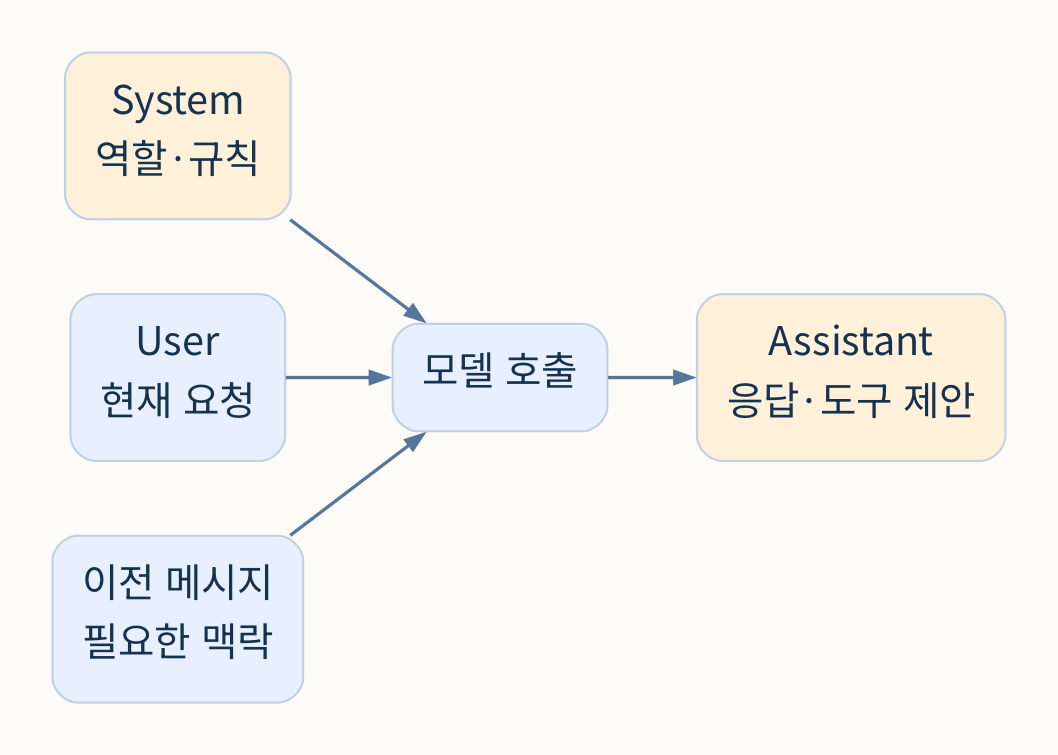

**그림 1.2.3.1 — 역할과 필요한 맥락이 한 요청을 이룹니다**

세 입력은 같은 모델 호출을 구성합니다. 이전 대화를 보관하는 책임은 애플리케이션에 있습니다.

**보면서 확인:** 두 번째 요청에 이전 메시지를 보내지 않으면 무엇이 빠지는지 말해 보세요.

**표현 범위:** 구체적인 메시지 역할 지원과 API 필드 이름은 사용하는 서비스에서 확인합니다.


In [ ]:
import httpx
messages = [
    {"role": "system", "content": "초보자에게 근거를 구분해 설명하세요."},
    {"role": "user", "content": "Agent의 도구 실행은 누가 하나요?"},
]
def mock_chat(request):
    return httpx.Response(200, json={"choices": [{"message": {"role": "assistant", "content": "[모의 응답] 프로그램이 도구를 실행합니다."}}]})
with httpx.Client(transport=httpx.MockTransport(mock_chat), base_url="https://training.invalid") as client:
    response = client.post("/chat/completions", json={"model": "teaching-mock", "messages": messages})
    response.raise_for_status()
    print(response.json()["choices"][0]["message"]["content"])


**실행에서 볼 것**

메시지 목록은 요청 본문에 있고, 답변은 응답의 choices 안에 있습니다. 이 모의 응답 형식은 Chat Completions 예이며 모든 API가 같은 응답을 쓰지는 않습니다.


**CodeMate와 확인하기**

> mock_chat이 401, 429, 500을 반환하는 경우를 추가해 주세요. 상태 코드별로 인증 확인·요청 빈도 조정·서버 상태 확인을 구별하고, 모든 오류를 무제한 재시도하지 마세요. 요청 본문의 키 값이나 인증 헤더를 출력하지 마세요.


### 1.2.4 대화 유지와 스트리밍

대화를 이어가려면 이전 User·Assistant 메시지를 다음 요청에 포함하거나 서비스가 제공하는 대화 상태 기능을 사용해야 합니다. 아래는 애플리케이션이 메시지 목록을 관리하는 방식입니다. 사용자 A와 B의 목록을 섞지 않아야 합니다.

스트리밍은 완성된 응답 전체를 기다리는 대신 작은 조각을 받는 방식입니다. 화면에는 조각을 이어 보여 주고, 대화 기록에는 최종 완성된 응답을 저장합니다. 중간 실패가 나면 미완성 응답임을 표시할 필요가 있습니다.

아래 모의 스트림은 이미 정해진 문자열을 나눠 돌려줍니다. 실제 모델의 생성 속도나 토큰 단위를 나타내지 않습니다. 응답을 누적하고 다음 대화에 넘기는 코드를 확인합니다.


In [ ]:
conversation = [{"role": "system", "content": "간결하게 설명하세요."}]
conversation.append({"role": "user", "content": "내 실습 주제는 RAG야."})
chunks = ["[모의 응답] ", "RAG는 ", "검색 근거를 ", "활용합니다."]
full_answer = ""
for chunk in chunks:
    full_answer += chunk
    print(chunk, end="")
conversation.append({"role": "assistant", "content": full_answer})
conversation.append({"role": "user", "content": "내 주제에서 출처가 왜 중요해?"})
print("\n다음 요청에 보낼 역할:", [m["role"] for m in conversation])


**실행에서 볼 것**

최종 응답은 한 번만 기록됩니다. 조각마다 Assistant 메시지를 새로 만들면 대화가 불필요하게 늘어납니다.


**CodeMate와 확인하기**

> 사용자별 conversation을 관리하는 함수를 만들어 주세요. A와 B의 대화가 섞이지 않는 사례와 스트림 중간 오류 사례를 보여 주세요. 실패한 답변을 완성된 답변으로 저장하지 마세요.


### 1.2.5 직접 호출과 공통 모델 설정

직접 HTTP 호출은 요청과 응답을 이해하는 데 유용합니다. SDK는 요청 작성·응답 객체·예외 처리를 도와주며, LangChain의 모델 인터페이스는 프롬프트와 도구 연결을 공통 방식으로 다룰 수 있게 합니다. 어느 단계든 서비스별 지원 기능은 확인해야 합니다.

이 프로젝트의 `get_llm()`은 환경변수에 따라 사내 모델 또는 OpenAI를 선택합니다. 호출하는 수업 코드는 같은 형태를 유지하고, 주소·모델명·인증은 설정에 둡니다. “OpenAI 호환”은 모든 모델 파라미터와 도구 기능까지 동일하다는 뜻이 아닙니다.

아래 기본값은 `FakeListChatModel`로 고정 답변을 반환합니다. 실제 연결을 준비한 경우 노트북 처음의 `RUN_LIVE=True`를 선택하고 처음부터 실행합니다. 오류가 나면 설정과 원인을 확인하며 모의 응답으로 조용히 바꾸지 않습니다.


In [ ]:
from langchain_core.language_models.fake_chat_models import FakeListChatModel
if RUN_LIVE:
    from config.llm import get_llm
    chat_model = get_llm()
else:
    chat_model = FakeListChatModel(responses=["[모의 모델] 모델은 제안하고 프로그램은 검사·실행합니다."])
reply = chat_model.invoke(messages)
print(reply.content)


**실행에서 볼 것**

모의 모드에서는 질문을 바꿔도 준비된 답변이 나옵니다. 이를 모델의 이해 능력으로 해석하지 마세요.


**CodeMate와 확인하기**

> config/llm.py를 읽고 모델 선택, 필수 환경변수 확인, 사내 헤더 설정이 어디 있는지 설명해 주세요. 실습 코드에 모델명이나 키를 새로 하드코딩하지 마세요. 모의 모드와 실제 모델 모드를 화면에서 구분할 문구도 제안해 주세요.


## 1.3 LangChain으로 흐름 연결하기

**이 블록의 결과물:** 프롬프트·모델·파서, 도구 스키마, 구조화 출력, 세션 기억을 조합한 작은 Agent를 검토합니다.


### 1.3.1 Runnable과 LCEL의 입출력

Runnable은 호출할 수 있는 구성요소를 같은 인터페이스로 다루는 단위입니다. `invoke`는 한 입력, `batch`는 여러 입력, `stream`은 출력 조각을 다룹니다. `|`는 앞 단계의 출력을 뒤 단계의 입력으로 넘깁니다.

프롬프트는 입력 사전에서 메시지를 만들고, 모델은 메시지를 받아 AIMessage를 돌려주며, 파서는 필요한 문자열이나 객체를 추출합니다. 중간 결과의 타입을 확인하면 연결이 왜 실패했는지 찾기 쉽습니다.

`RunnableLambda`는 일반 함수를 연결하고, `RunnablePassthrough`는 입력을 유지하며, `RunnableParallel`은 여러 결과를 사전으로 모읍니다. 먼저 간단한 체인을 완성한 뒤 필요한 변환만 추가합니다.


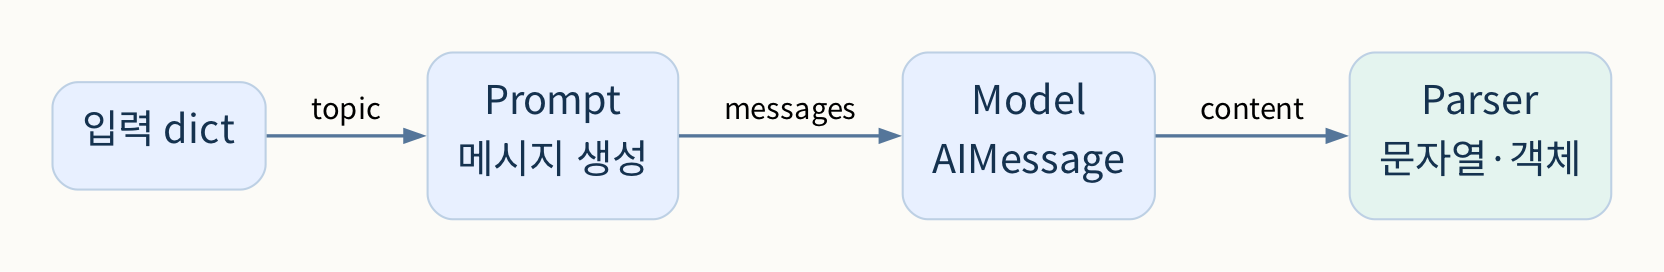

**그림 1.3.1.1 — 연결선마다 전달하는 값이 달라집니다**

입력 사전이 메시지로, AIMessage가 파서 결과로 바뀝니다. 오류를 찾을 때 각 단계의 실제 값을 확인합니다.

**보면서 확인:** 프롬프트와 파서 사이에 모델이 필요한 이유를 말해 보세요.

**표현 범위:** 병렬 분기나 외부 검색이 없는 최소 체인입니다.


In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnableParallel
prompt = ChatPromptTemplate.from_messages([
    ("system", "초보자에게 한 문장으로 설명하세요."),
    ("human", "{topic}의 역할은 무엇인가요?"),
])
chain = prompt | chat_model | StrOutputParser()
print(chain.invoke({"topic": "도구 검사"}))
inspect_input = RunnableParallel(original=RunnableLambda(lambda x: x), length=RunnableLambda(lambda x: len(x)))
print(inspect_input.invoke("Agent"))


**실행에서 볼 것**

모델을 통과하기 전후에 입력 타입이 바뀝니다. 모의 응답의 문장이 그대로여도 Runnable의 연결과 파싱은 실제로 실행됩니다.


**CodeMate와 확인하기**

> topic 앞뒤 공백을 정리하는 RunnableLambda를 체인의 처음에 추가해 주세요. 입력은 {"topic": str}이고 출력은 문자열이어야 합니다. 빈 topic을 거절하고 invoke와 batch를 각각 실행해 검증하세요.


### 1.3.2 도구 스키마와 실제 Agent 실행

`@tool`은 함수의 이름·설명·타입을 도구 스키마로 만듭니다. 모델은 이 정보를 보고 사용할 도구와 인자를 선택합니다. 설명에는 무엇을 하는지와 언제 사용할지가 드러나야 합니다.

LangChain의 `create_agent`는 모델→도구→모델 반복을 구성합니다. `bind_tools`는 도구 정보를 모델에 전달하는 연결이며, 함수를 즉시 실행하는 명령이 아닙니다. 반환 메시지 목록에서 AIMessage의 tool_calls와 ToolMessage의 결과를 구별해 읽어 보세요.

모의 모드에서는 `ScriptedMultiplyModel`이 정수 두 개를 찾아 multiply를 요청합니다. 이는 도구 호출 경로를 재현하는 대역입니다. 실제 연결에서는 환경에서 선택한 모델이 요청합니다.


In [ ]:
from langchain_core.tools import tool
from langchain.agents import create_agent
from courseware.models import ScriptedMultiplyModel
@tool
def multiply(a: int, b: int) -> int:
    """두 정수의 곱을 계산한다. 계산 결과가 필요할 때 사용한다."""
    return a * b
agent_model = chat_model if RUN_LIVE else ScriptedMultiplyModel()
multiply_agent = create_agent(model=agent_model, tools=[multiply])
agent_result = multiply_agent.invoke({"messages": [{"role": "user", "content": "6과 7을 곱해줘"}]})
for message in agent_result["messages"]:
    print(message.type, message.content, getattr(message, "tool_calls", []))


**실행에서 볼 것**

Human→도구 호출 AI→Tool→최종 AI 순서가 보입니다. 42는 도구가 계산한 결과입니다.


**CodeMate와 확인하기**

> multiply의 허용 입력 범위를 -1000 이상 1000 이하로 제한해 주세요. 도구 스키마와 함수 실행 검사를 함께 살펴보고, 경계값·범위 밖·문자열 입력의 처리 결과를 비교하세요. 모의 모델이 항상 범위 안 값을 만들 거라고 가정하지 마세요.


### 1.3.3 구조화 출력과 사실 검증

모델의 출력이 다음 프로그램의 입력이 되면 문장보다 정해진 구조가 편리합니다. 예를 들어 검토 결과는 주제, 출처 ID 목록, 추가 확인 여부를 가지는 객체로 만들 수 있습니다. JSON을 읽는 단계와 필드의 타입·누락을 검사하는 단계는 구별됩니다.

Pydantic은 입력 계약을 코드로 표현합니다. 엄격한 타입, 범위, 필수 필드 등을 정할 수 있습니다. 다만 형식 검사가 통과했다고 문서 ID가 실제 존재하거나 내용이 사실이라는 뜻은 아닙니다. 외부 근거와 대조하는 검사가 추가로 필요합니다.

아래는 모델이 출력했다고 가정한 두 JSON을 비교합니다. 하나는 형식이 맞고, 하나는 필드가 빠져 있습니다. 정상 출력에도 잘못된 출처가 들어갈 수 있다는 점을 다음 RAG 블록과 연결하세요.


In [ ]:
from pydantic import BaseModel, ConfigDict, Field, ValidationError
class ReviewResult(BaseModel):
    model_config = ConfigDict(strict=True, extra="forbid")
    topic: str = Field(min_length=1)
    source_ids: list[str]
    needs_review: bool
for raw in ['{"topic":"Agent","source_ids":["D1"],"needs_review":true}', '{"topic":"Agent","source_ids":"D999"}']:
    try:
        print(ReviewResult.model_validate_json(raw).model_dump())
    except ValidationError as error:
        print("검증 실패:", [e["loc"] for e in error.errors()])


**실행에서 볼 것**

누락된 needs_review와 잘못된 source_ids 타입이 검출됩니다. D999가 리스트에 들어오면 형식만으로는 존재 여부를 알 수 없습니다.


**CodeMate와 확인하기**

> 허용 출처 집합 {D1, D2, D3}과 대조하는 별도 함수를 추가해 주세요. JSON 형식 실패, 스키마 실패, 출처 존재 실패를 구별해 결과를 보여 주세요. 출처가 있다는 이유만으로 답변 내용까지 참이라고 표시하지 마세요.


### 1.3.4 대화 기억과 세션 경계

이 절은 원본 교안의 RunnableWithMessageHistory를 비교 학습하기 위한 예제입니다. 현재 설치 버전에서는 deprecation 경고가 나옵니다. 새 구현에는 2.2.4와 3.4.2의 LangGraph Checkpointer를 사용하세요.

Buffer는 이전 메시지를 그대로 보관합니다. Summary는 메시지를 요약해 줄입니다. 검색 기반 기억은 관련 기록만 찾아 입력에 넣습니다. 세 방식 모두 다음 호출에 필요한 맥락을 준비하는 설계이며 장단점이 다릅니다.

`RunnableWithMessageHistory`는 세션 ID로 메시지 저장소를 찾고 호출 앞뒤의 기록을 관리합니다. 이 예제는 메모리 안에 저장하므로 커널을 다시 시작하면 사라집니다. 다음 날의 Checkpointer 실습에서는 그래프 실행 상태를 보관하는 방식을 살펴봅니다.

모의 모델은 저장된 이름을 이해해 답하지 않습니다. 대신 저장소의 실제 메시지 수와 세션별 내용을 확인해 기록 관리가 동작했는지 검증합니다.


In [ ]:
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory
histories = {}
def history_for(session_id):
    return histories.setdefault(session_id, InMemoryChatMessageHistory())
history_chat = RunnableWithMessageHistory(chat_model, history_for)
history_chat.invoke("내 주제는 RAG", config={"configurable": {"session_id": "A"}})
history_chat.invoke("내 주제는 MCP", config={"configurable": {"session_id": "B"}})
print({session: len(history.messages) for session, history in histories.items()})
assert histories["A"].messages[0].content != histories["B"].messages[0].content


**실행에서 볼 것**

A와 B의 메시지가 각각 보관됩니다. 단일 전역 메시지 목록을 쓰면 사용자 맥락이 섞일 수 있습니다.


**CodeMate와 확인하기**

> 세션 A에 질문을 하나 더 보내고 B의 메시지 수가 바뀌지 않는지 확인해 주세요. 오래된 대화를 요약할 때 반드시 유지할 업무 상태 2가지를 제안하되, 모의 모델이 실제 요약했다고 주장하지 마세요.


### 1.3.5 첫 Agent를 CodeMate와 검토하기

오늘의 구성요소를 연결하면 입력 사전→메시지→모델의 도구 제안→도구 실행→결과 메시지→최종 답변이 됩니다. 각 단계가 정상인지는 결과 문장 하나로 판단하지 않고 중간 기록과 계약을 확인합니다.

CodeMate에 “Agent를 만들어 줘”라고만 요청하면 구현 범위와 성공 기준이 모호합니다. 현재 파일, 입력·출력, 사용할 도구, 변경하지 않을 경계, 실행할 검증을 함께 알려 주세요. 생성된 코드를 읽고 실행 결과를 본 뒤 수정 지시를 구체화합니다.

아래는 모의 실행의 최소 검증입니다. 실제 모델 모드에서는 문장이 달라질 수 있으므로 문장 전체의 동일성보다 도구 호출·인자·결과의 관계를 검토합니다.


In [ ]:
from langchain_core.messages import ToolMessage
outputs = [m.content for m in agent_result["messages"] if isinstance(m, ToolMessage)]
print("도구 결과:", outputs)
if not RUN_LIVE:
    assert outputs == ["42"]
    assert "42" in agent_result["messages"][-1].content
print("오늘의 검토: 입력 계약 → 도구 실행 → 결과 근거")


**CodeMate와 확인하기**

> 1.3.2의 곱셈 Agent를 기준으로 입력 누락, 정수 두 개, 음수, 허용 범위 밖 사례를 검토해 주세요. 수정 계획을 먼저 쓰고 최소 변경으로 구현하세요. 실행 결과에 tool 호출과 최종 답변을 구분하고, 실패를 성공으로 처리하지 않는지 확인하세요. 마지막에 내가 직접 읽어야 할 함수 2개를 짚어 주세요.

**완료 기준:** 도구 결과 42가 어디서 나왔는지 설명하고, 실패 입력 하나를 재현합니다. **확장:** 도구를 하나 추가하기 전에 선택 기준과 충돌 가능성을 적습니다.


**다음 연결**

2일차에는 도구 결과를 문서 검색으로 확장하고, 분기·상태·사람의 승인·사용자 화면을 하나씩 연결합니다.

**원본 연결:** [1-1 PDF](../docs/raw/Chapter01/day01/1-1-ai-agent-design-thinking.pdf), [1-2 PDF](../docs/raw/Chapter01/day01/1-2-development-environment-and-llm-api-mechanism.pdf), [1-3 PDF](../docs/raw/Chapter01/day01/1-3-langchain-framework-deep-dive.pdf). 원본 실습은 `src/raw/Chapter01/01-llm-api/`, `src/raw/Chapter01/02-langchain/`입니다.
